# Autoscaler fuzzy (malha fechada) — Notebook final

> Projeto final — Inteligência Computacional (CESUPA)
> Autor: Gustavo Teixeira Bittencourt

## Declaração de uso de IA generativa

Este projeto foi desenvolvido com apoio de IA generativa (**Claude Code**,
modelo **Claude Sonnet 5**, Anthropic), em papel de mentor/par de
programação: a IA implementou o código (modelagem fuzzy, ambiente de
simulação, loop de malha fechada, baselines, métricas e visualizações) a
partir de requisitos e decisões de modelagem discutidos com o autor.

O autor revisou, validou e estudou cada decisão de modelagem antes de
aceitá-la — domínios e formas das funções de pertinência, critério de
construção da base de 27 regras, equações do ambiente (fila, atraso de
provisionamento, SLO) e definição das métricas estão documentados e
justificados em [`docs/SPEC.md`](../docs/SPEC.md) e
[`docs/DECISOES.md`](../docs/DECISOES.md) — escritos exatamente para que o
autor consiga defender o trabalho na apresentação sem depender da IA. O
registro sessão a sessão de como a IA foi usada em cada fase está em
[`AI_USAGE_LOG.md`](../AI_USAGE_LOG.md).

O autor é responsável pelo conteúdo final deste notebook e do projeto.

## Visão geral

Controlador fuzzy (Mamdani) que decide, a cada passo de tempo, quantas
instâncias de um servidor adicionar ou remover, com base no estado
observado do sistema (uso de CPU, tamanho da fila de requisições por
instância, tendência de curto prazo da carga). O ambiente (fila +
instâncias) evolui segundo um modelo determinístico (dado um seed); o
próximo estado realimenta o controlador no passo seguinte, formando a
malha fechada. Dois baselines (if/else por limiar de CPU, estilo
Kubernetes HPA, e PID) servem de referência para comparação.

Este notebook percorre, nesta ordem:

1. Casos de teste comentados do controlador fuzzy (malha aberta).
2. Superfícies de controle (malha aberta).
3. Evolução no tempo da malha fechada, com pico de tráfego e duas condições
   iniciais.
4. Comparação com os baselines (tabela de métricas).
5. Painel interno do fuzzy (bônus): inferência Mamdani passo a passo.
6. Animação em tempo real da malha fechada (bônus).


In [1]:
import os
import sys

sys.path.insert(0, os.path.join(os.getcwd(), "..", "src"))

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
plt.rcParams["figure.dpi"] = 100


In [2]:
from baselines import ConfigLimiar, ConfigPID, ControladorLimiar, ControladorPID
from environment import ConfigAmbiente
from fuzzy_controller import controlador_padrao
from metrics import formatar_tabela, tabela_comparativa
from simulation import avaliar, plotar_evolucao, simular
from viz.inner_panel import figura_painel_interno
from viz.realtime import animar_malha_fechada


## 1. Controlador fuzzy — casos de teste (malha aberta)

Quatro observações (`cpu`, `fila`, `tendencia`) escolhidas para cobrir os
extremos e o ponto de equilíbrio da base de regras (mesmas combinações
comentadas em `fuzzy_controller._NOTAS` e em `docs/SPEC.md`, seção 3), e
mais um caso que ilustra explicitamente o combate à oscilação.

In [3]:
controlador = controlador_padrao()

casos = [
    (
        "Pico de tráfego claro",
        {"cpu": 90.0, "fila": 35.0, "tendencia": 14.0},
        "cpu alta + fila grande + tendência subindo -> reage com força máxima",
    ),
    (
        "Ociosidade clara",
        {"cpu": 15.0, "fila": 2.0, "tendencia": -12.0},
        "cpu baixa + fila pequena + tendência caindo -> economiza custo",
    ),
    (
        "Ponto de equilíbrio",
        {"cpu": 50.0, "fila": 15.0, "tendencia": 0.0},
        "todas as entradas no conjunto médio -> mantém",
    ),
    (
        "Evita oscilação",
        {"cpu": 85.0, "fila": 3.0, "tendencia": -15.0},
        "cpu alta momentânea, mas fila vazia e carga já caindo -> não justifica manter capacidade extra",
    ),
]

for nome, obs, explicacao in casos:
    delta = controlador.decidir(obs)
    print(f"{nome}:")
    print(f"  observação = {obs}")
    print(f"  delta decidido = {delta:+d}   ({explicacao})")
    print()


Pico de tráfego claro:
  observação = {'cpu': 90.0, 'fila': 35.0, 'tendencia': 14.0}
  delta decidido = +2   (cpu alta + fila grande + tendência subindo -> reage com força máxima)

Ociosidade clara:
  observação = {'cpu': 15.0, 'fila': 2.0, 'tendencia': -12.0}
  delta decidido = -2   (cpu baixa + fila pequena + tendência caindo -> economiza custo)

Ponto de equilíbrio:
  observação = {'cpu': 50.0, 'fila': 15.0, 'tendencia': 0.0}
  delta decidido = +0   (todas as entradas no conjunto médio -> mantém)

Evita oscilação:
  observação = {'cpu': 85.0, 'fila': 3.0, 'tendencia': -15.0}
  delta decidido = -1   (cpu alta momentânea, mas fila vazia e carga já caindo -> não justifica manter capacidade extra)



## 2. Superfícies de controle (malha aberta)

Resposta estática do controlador (sem o ambiente) variando um par de
entradas por vez, com a terceira fixa no ponto médio do seu domínio —
3 superfícies: `(cpu, fila)`, `(cpu, tendencia)` e `(fila, tendencia)`.

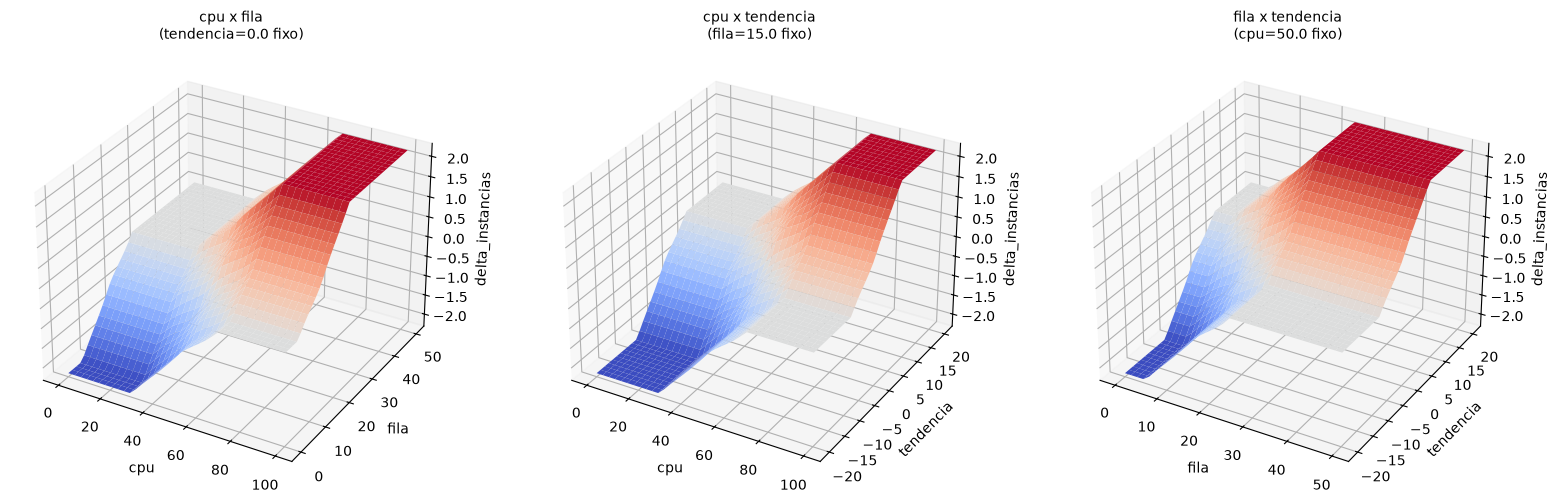

In [4]:
def superficie(eixo_x, eixo_y, fixo, resolucao=35):
    """`eixo_x`/`eixo_y`: ("nome", (min, max)). `fixo`: {"nome": valor}
    para a terceira entrada."""
    nome_x, dom_x = eixo_x
    nome_y, dom_y = eixo_y
    xs = np.linspace(*dom_x, resolucao)
    ys = np.linspace(*dom_y, resolucao)
    zs = np.zeros((resolucao, resolucao))
    for i, y in enumerate(ys):
        for j, x in enumerate(xs):
            obs = {nome_x: x, nome_y: y, **fixo}
            zs[i, j] = controlador.decidir_continuo(obs)
    return xs, ys, zs


configs_superficie = [
    (("cpu", (0.0, 100.0)), ("fila", (0.0, 50.0)), {"tendencia": 0.0}),
    (("cpu", (0.0, 100.0)), ("tendencia", (-20.0, 20.0)), {"fila": 15.0}),
    (("fila", (0.0, 50.0)), ("tendencia", (-20.0, 20.0)), {"cpu": 50.0}),
]

fig = plt.figure(figsize=(16, 5))
for i, (eixo_x, eixo_y, fixo) in enumerate(configs_superficie, start=1):
    xs, ys, zs = superficie(eixo_x, eixo_y, fixo)
    X, Y = np.meshgrid(xs, ys)
    ax = fig.add_subplot(1, 3, i, projection="3d")
    ax.plot_surface(X, Y, zs, cmap="coolwarm", linewidth=0, antialiased=True)
    ax.set_xlabel(eixo_x[0])
    ax.set_ylabel(eixo_y[0])
    ax.set_zlabel("delta_instancias")
    fixo_str = ", ".join(f"{k}={v}" for k, v in fixo.items())
    ax.set_title(f"{eixo_x[0]} x {eixo_y[0]}\n({fixo_str} fixo)", fontsize=10)
fig.tight_layout()
plt.show()


## 3. Malha fechada — evolução no tempo

Cenário com pico de tráfego (`pico_amplitude=60`, 30 passos), comparando
duas condições iniciais: sistema **vazio** (`n_inicial=2`, `q_inicial=0`) e
sistema **com fila acumulada** (`n_inicial=2`, `q_inicial=300`).

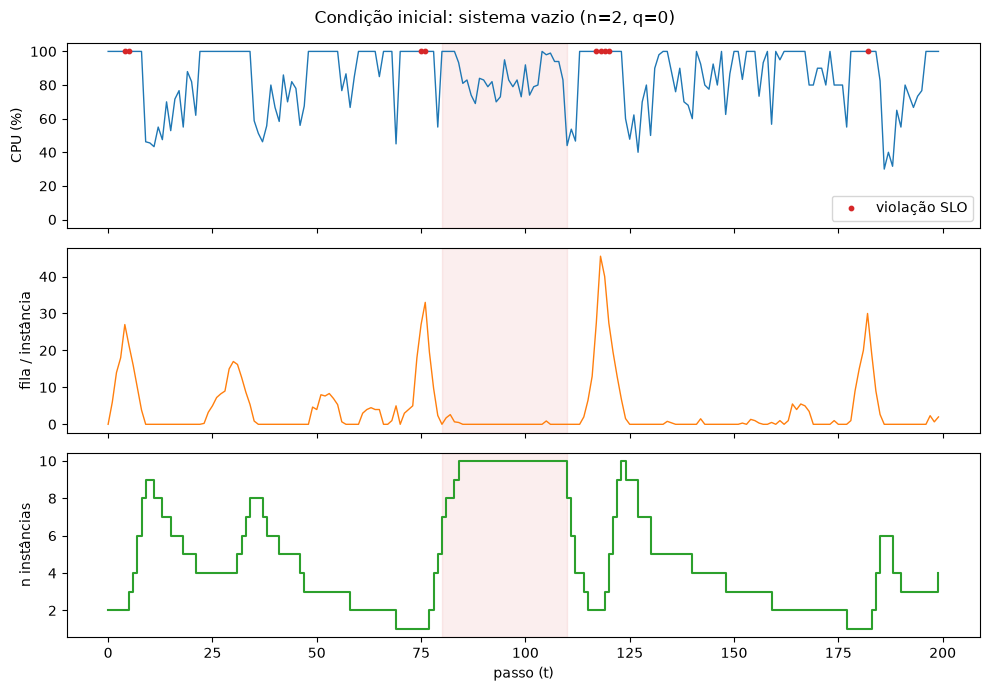

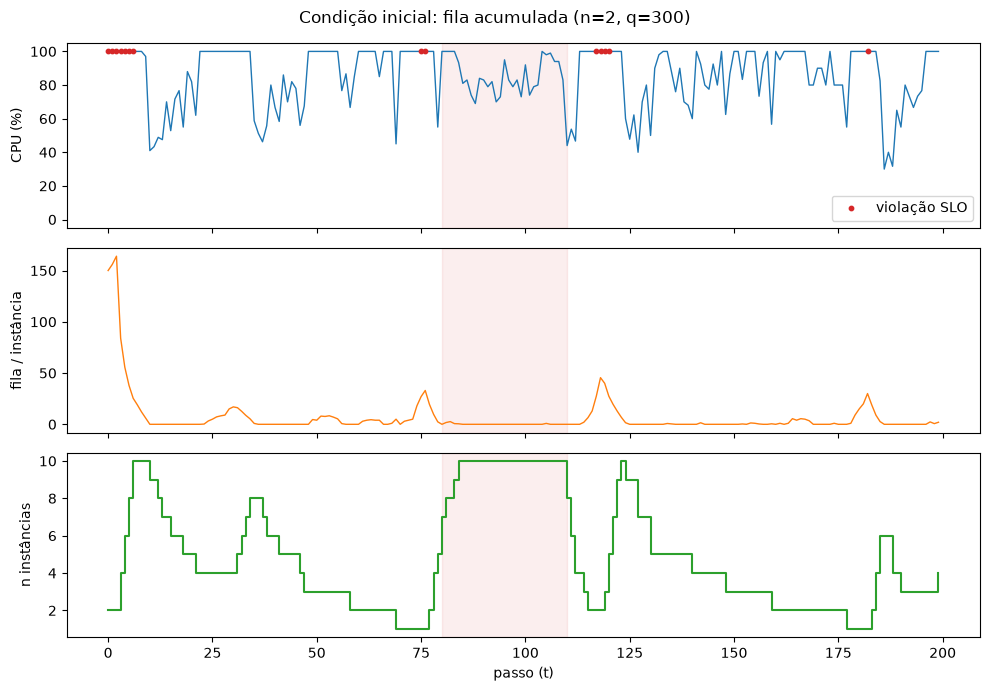

In [5]:
cfg_vazio = ConfigAmbiente(n_inicial=2, q_inicial=0.0, pico_inicio=80, pico_duracao=30, pico_amplitude=60.0)
cfg_cheio = ConfigAmbiente(n_inicial=2, q_inicial=300.0, pico_inicio=80, pico_duracao=30, pico_amplitude=60.0)

resultado_vazio = simular(controlador_padrao(), config=cfg_vazio, seed=7, passos=200)
resultado_cheio = simular(controlador_padrao(), config=cfg_cheio, seed=7, passos=200)

plotar_evolucao(resultado_vazio, config=cfg_vazio, titulo="Condição inicial: sistema vazio (n=2, q=0)")
plt.show()

plotar_evolucao(resultado_cheio, config=cfg_cheio, titulo="Condição inicial: fila acumulada (n=2, q=300)")
plt.show()


In [6]:
print("vazio :", avaliar(controlador_padrao(), config=cfg_vazio, seed=7, passos=200))
print("cheio :", avaliar(controlador_padrao(), config=cfg_cheio, seed=7, passos=200))


vazio : {'slo_violations': 0.045, 'cost': 949.0, 'fila_maxima': 137.0, 'num_mudancas_escala': 71}


cheio : {'slo_violations': 0.07, 'cost': 974.0, 'fila_maxima': 336.0, 'num_mudancas_escala': 74}


## 4. Comparação com os baselines

Os 3 controladores (fuzzy, limiar se/então estilo HPA, PID) rodam no
**mesmo cenário e seed** (pico de tráfego) para uma comparação justa — ver
discussão do trade-off custo×SLO em `docs/DECISOES.md`, seção "Fase 4".

In [7]:
cfg_comparacao = ConfigAmbiente(pico_inicio=80, pico_duracao=30, pico_amplitude=60.0)

controladores = {
    "fuzzy": controlador_padrao(),
    "limiar": ControladorLimiar(ConfigLimiar()),
    "pid": ControladorPID(ConfigPID()),
}

resultados = tabela_comparativa(controladores, config=cfg_comparacao, seed=3, passos=200)
print(formatar_tabela(resultados))


controlador | pct_violacao_slo | custo   | fila_maxima | num_mudancas_escala | tempo_recuperacao
fuzzy       | 6.50             | 869.00  | 282.00      | 65                  | -                
limiar      | 4.50             | 1231.00 | 274.00      | 73                  | 0.00             
pid         | 3.50             | 1093.00 | 221.00      | 108                 | 0.00             


## 5. Painel interno do fuzzy (bônus)

Inferência Mamdani passo a passo para uma observação específica: grau de
pertinência ativado em cada conjunto das 3 entradas, conjunto agregado de
saída e centroide (ver `src/viz/inner_panel.py`).

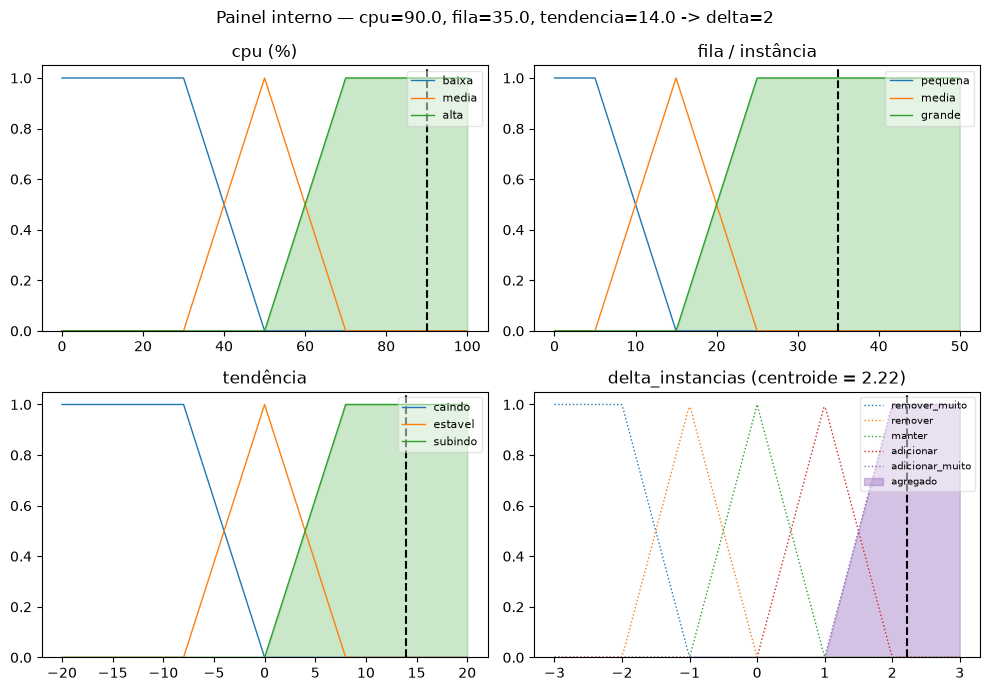

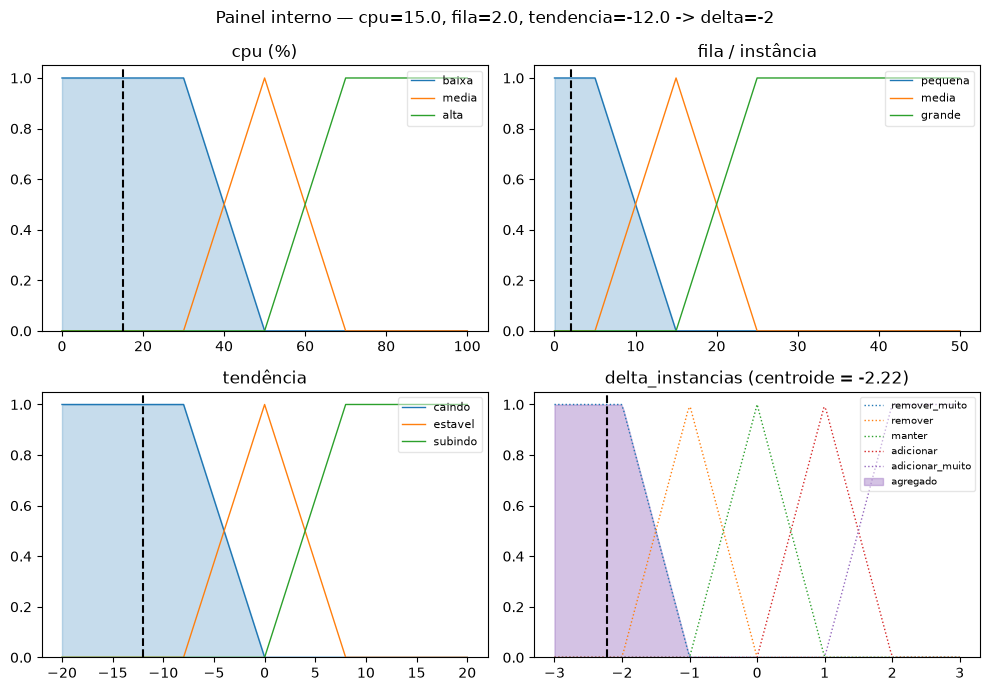

In [8]:
figura_painel_interno(controlador_padrao(), {"cpu": 90.0, "fila": 35.0, "tendencia": 14.0})
plt.show()

figura_painel_interno(controlador_padrao(), {"cpu": 15.0, "fila": 2.0, "tendencia": -12.0})
plt.show()


## 6. Animação em tempo real da malha fechada (bônus)

Versão animada do gráfico da Seção 3 (ver `src/viz/realtime.py`). O GIF
completo (180 passos) usado na demonstração está em
[`docs/demo_malha_fechada.gif`](../docs/demo_malha_fechada.gif):

![demo da malha fechada](../docs/demo_malha_fechada.gif)

Abaixo, uma versão curta gerada e renderizada diretamente neste notebook:

In [9]:
from IPython.display import HTML

cfg_demo = ConfigAmbiente(pico_inicio=40, pico_duracao=20, pico_amplitude=50.0)
resultado_demo = simular(controlador_padrao(), config=cfg_demo, seed=1, passos=90)
anim = animar_malha_fechada(resultado_demo, config=cfg_demo, titulo="Malha fechada (versão curta)", passo_frame=3)
html_anim = HTML(anim.to_jshtml())
plt.close(anim._fig)
html_anim


## 7. Conclusão

O controlador fuzzy Mamdani combina as 3 entradas (`cpu`, `fila`,
`tendencia`) com pertinência parcial, evitando tanto a reação tardia de um
controlador baseado só em CPU quanto a oscilação nas bordas de um
if/else por limiar. Na comparação da Seção 4, o fuzzy teve o menor custo
às custas de alguma violação de SLO — um trade-off explícito (ver
`docs/DECISOES.md`), que é exatamente o ponto de partida da extensão
futura do projeto: otimização multiobjetivo (NSGA-II) dos parâmetros das
funções de pertinência, tendo `slo_violations` e `cost` (já expostos por
`simulation.avaliar`) como os dois objetivos.